<img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;">

# 01_04 Ensembles 


## 1. Bagging and Random Forest

### Step 1.1: Bagging with Decision Trees

**Bagging** (bootstrap aggregating) trains many trees on different bootstrap samples and averages their predictions. This reduces variance and usually improves generalization over a single tree.

**What to do**
1. Create a `BaggingClassifier` with a `DecisionTreeClassifier(random_state=42)`.
2. Fit on the Breast Cancer training set.
3. Print train/test accuracy.

Has the accuracy improved with respect to using a single tree?


In [94]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import train_test_split

# Create a decision tree classifier
dt = DecisionTreeClassifier(random_state=42)

# Create a bagging classifier
bg = BaggingClassifier(
    estimator=dt,
    random_state=42
)

# Load the breast cancer dataset
data = load_breast_cancer()

X_train, X_test, y_train, y_test = train_test_split(
    data.data,
    data.target,
    test_size=0.3,
    random_state=42,
    stratify=data.target
)

# Fit the bagging classifier
bg.fit(X_train, y_train)

# Compute accuracy
train_accuracy = bg.score(X_train, y_train)
test_accuracy = bg.score(X_test, y_test)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")






Training Accuracy: 1.0000
Testing Accuracy: 0.9591


Yes. The accuracy improved compared with using a single decision tree. Bagging combines the predictions of multiple decision trees trained on different bootstrap samples, reducing the variance of the model and improving its generalization performance.

### Step 1.2: Random Forest (bagging + random subspace)

A Random Forest adds feature randomness at each split (`max_features`) and often improving performance further.

**What to do**
1. Fit `RandomForestClassifier` on the Breast Cancer training set.
2. Print train/test accuracy; plot the decision boundary.
3. Access and print `.feature_importances_`.
4. Sort importances in a descending order and plot a horizontal bar chart with feature names. Are there changes with respect to a single tree?

Random Forest Training Accuracy: 1.0000
Random Forest Testing Accuracy: 0.9357


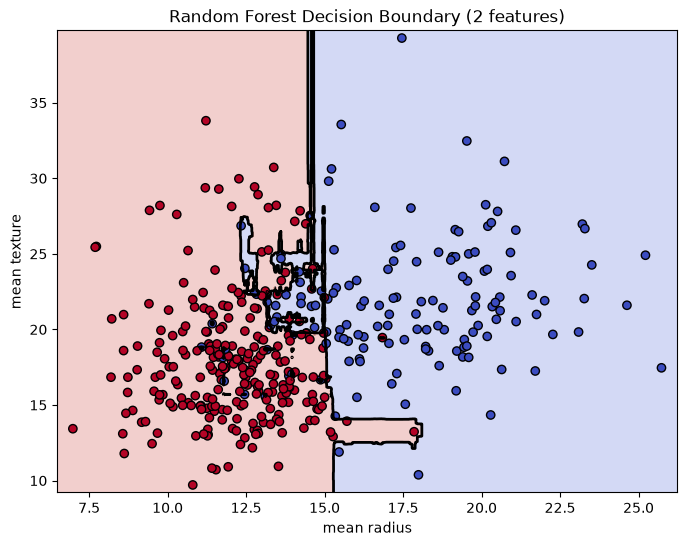

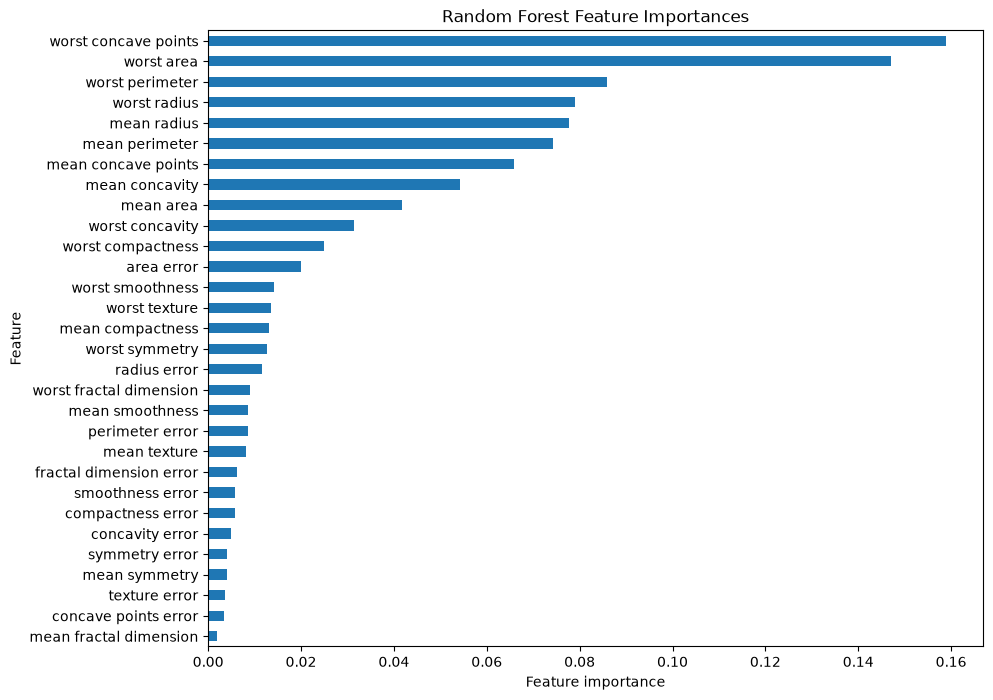

In [95]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import numpy as np

# Create a random forest classifier using all features
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

print(f"Random Forest Training Accuracy: {rf.score(X_train, y_train):.4f}")
print(f"Random Forest Testing Accuracy: {rf.score(X_test, y_test):.4f}")

# Train a separate 2D model so its decision boundary can be plotted
feature_indices = [0, 1]
X_train_2d = X_train[:, feature_indices]
rf_2d = RandomForestClassifier(random_state=42)
rf_2d.fit(X_train_2d, y_train)

x_min, x_max = X_train_2d[:, 0].min() - 0.5, X_train_2d[:, 0].max() + 0.5
y_min, y_max = X_train_2d[:, 1].min() - 0.5, X_train_2d[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

grid = np.c_[xx.ravel(), yy.ravel()]
probability = rf_2d.predict_proba(grid)[:, 1].reshape(xx.shape)
prediction = rf_2d.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, prediction, alpha=0.25, cmap="coolwarm")
plt.contour(xx, yy, probability, levels=[0.5], colors="black", linewidths=2)
plt.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=y_train,
    edgecolor="k",
    cmap="coolwarm"
)

plt.xlabel(data.feature_names[0])
plt.ylabel(data.feature_names[1])
plt.title("Random Forest Decision Boundary (2 features)")
plt.show()

# Print and plot feature importances of the full random forest
feature_importances = pd.Series(
    rf.feature_importances_,
    index=data.feature_names
)
feature_importances.sort_values().plot(
    kind="barh",
    figsize=(10, 8)
)
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importances")
plt.show()

rf_importances = rf.feature_importances_



Yes. The feature importance values change compared with a single decision tree. In a Random Forest, each tree is trained using random subsets of the samples and features, so the importance is averaged across many trees. This generally produces more stable feature importance estimates than a single decision tree.

### Step 1.3: Study Random Forest parameters

Random Forests have several important hyperparameters that performance and interpretability.  
We’ll sweep a few to see their impact.

**What to do**
1. Number of trees (`n_estimators`) train forests with `[10, 50, 100, 200, 500]`; plot train/test accuracy vs the number of trees.
2. Splitting criterion: compare `criterion="gini"` (default) vs `criterion="entropy"`; report test accuracy for each.
3. Tree depth (`max_depth`): compare shallow forests (`max_depth=3`) vs unrestricted depth (`None`); see how it affects overfitting.
4. Minimum samples per leaf (`min_samples_leaf`): try values `[1, 5, 10]`; note how increasing this regularizes the forest.

In general, more trees stabilize performance, deeper trees risk overfitting, larger leaves and entropy/gini choices influence splits but often with minor differences.


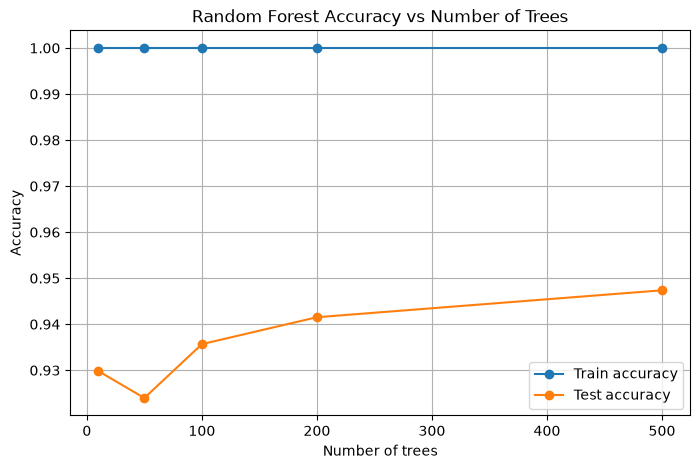

Criterion: gini
Test accuracy: 0.9357
Criterion: entropy
Test accuracy: 0.9415
Max depth: 3
Train accuracy: 0.9824
Test accuracy: 0.9357

Max depth: None
Train accuracy: 1.0000
Test accuracy: 0.9357

Min samples per leaf: 1
Train accuracy: 1.0000
Test accuracy: 0.9357

Min samples per leaf: 5
Train accuracy: 0.9824
Test accuracy: 0.9357

Min samples per leaf: 10
Train accuracy: 0.9724
Test accuracy: 0.9298



In [96]:
n_estimators_values = [10, 50, 100, 200, 500]

train_accuracies = []
test_accuracies = []

for n in n_estimators_values:
    rf = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )
    
    rf.fit(X_train, y_train)
    
    train_accuracies.append(rf.score(X_train, y_train))
    test_accuracies.append(rf.score(X_test, y_test))

plt.figure(figsize=(8, 5))

plt.plot(
    n_estimators_values,
    train_accuracies,
    marker="o",
    label="Train accuracy"
)

plt.plot(
    n_estimators_values,
    test_accuracies,
    marker="o",
    label="Test accuracy"
)

plt.xlabel("Number of trees")
plt.ylabel("Accuracy")
plt.title("Random Forest Accuracy vs Number of Trees")
plt.legend()
plt.grid()
plt.show()

criteria = ["gini", "entropy"]

for criterion in criteria:
    rf = RandomForestClassifier(
        criterion=criterion,
        random_state=42
    )
    
    rf.fit(X_train, y_train)
    
    test_accuracy = rf.score(X_test, y_test)
    
    print(f"Criterion: {criterion}")
    print(f"Test accuracy: {test_accuracy:.4f}")


depth_values = [3, None]

for depth in depth_values:
    rf = RandomForestClassifier(
        max_depth=depth,
        random_state=42
    )
    
    rf.fit(X_train, y_train)
    
    train_accuracy = rf.score(X_train, y_train)
    test_accuracy = rf.score(X_test, y_test)
    
    print(f"Max depth: {depth}")
    print(f"Train accuracy: {train_accuracy:.4f}")
    print(f"Test accuracy: {test_accuracy:.4f}")
    print()


leaf_values = [1, 5, 10]

for leaf in leaf_values:
    rf = RandomForestClassifier(
        min_samples_leaf=leaf,
        random_state=42
    )
    
    rf.fit(X_train, y_train)
    
    train_accuracy = rf.score(X_train, y_train)
    test_accuracy = rf.score(X_test, y_test)
    
    print(f"Min samples per leaf: {leaf}")
    print(f"Train accuracy: {train_accuracy:.4f}")
    print(f"Test accuracy: {test_accuracy:.4f}")
    print()



## 2. Boosting

### Step 2.1: AdaBoost vs Gradient Boosting

Boosting builds trees sequentially: each new tree focuses on errors of the current ensemble. AdaBoost: reweights misclassified points; often uses shallow trees (decision stumps) and Gradient Boosting fits each tree to residuals. 

**What to do**
1. Fit an `AdaBoostClassifier` with a decision stump (tree with maximum depth of 1) as base classifier and a `GradientBoostingClassifier` on the Breast Cancer training set.
2. Report training and test accuracy for both.
3. Compare to Random Forest: which generalizes better on this dataset?


In [97]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
# Create a gradient boosting classifier
ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train, y_train)

print(f"AdaBoost Training Accuracy: {ada.score(X_train, y_train):.4f}")
print(f"AdaBoost Testing Accuracy: {ada.score(X_test, y_test):.4f}")

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
print(f"Gradient Boosting Training Accuracy: {gb.score(X_train, y_train):.4f}")
print(f"Gradient Boosting Testing Accuracy: {gb.score(X_test, y_test):.4f}")

#3. Compare to Random Forest: which generalizes better on this dataset?





AdaBoost Training Accuracy: 1.0000
AdaBoost Testing Accuracy: 0.9591
Gradient Boosting Training Accuracy: 1.0000
Gradient Boosting Testing Accuracy: 0.9415



Random Forest has a test accuracy of **0.9357**, while AdaBoost achieves **0.9591** and Gradient Boosting achieves **0.9415**. Therefore, **AdaBoost generalizes best on this dataset**, because it obtains the highest test accuracy. Gradient Boosting performs slightly better than Random Forest, but both AdaBoost and Gradient Boosting show a gap between training and test accuracy, which indicates some overfitting.

### Step 2.2: Visualizing AdaBoost base classifiers on moons

On 2D moons dataset, boosting is easy to visualize. We can actually see the sequential refinement.

**What to do**
1. Fit AdaBoost with stumps (`max_depth=1`) on the moons dataset with 5 base classifiers.  
2. Access `.estimators_`: the list of fitted base classifiers (here: 5 stumps).  
3. Plot the decision boundary for each stump separately.  
4. Finally, plot the decision boundary of the whole AdaBoost ensemble  

Each stump alone is weak, but together they capture the complex moons shape.  


X shape: (400, 2), y shape: (400,)
AdaBoost Training Accuracy: 0.9036
AdaBoost Testing Accuracy: 0.9167
Number of weak learners: 5
First weak learner: DecisionTreeClassifier(max_depth=1, random_state=1608637542)


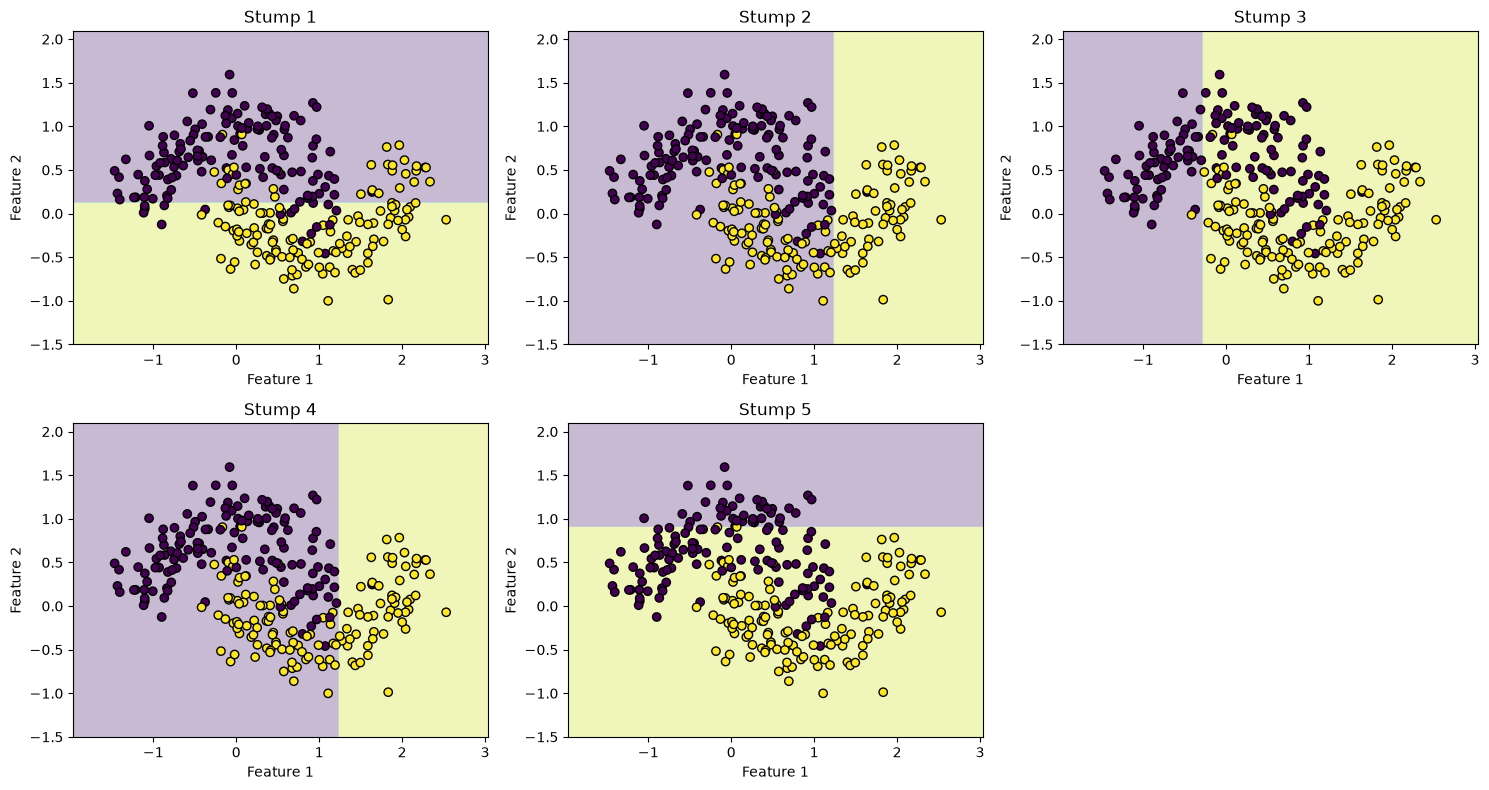

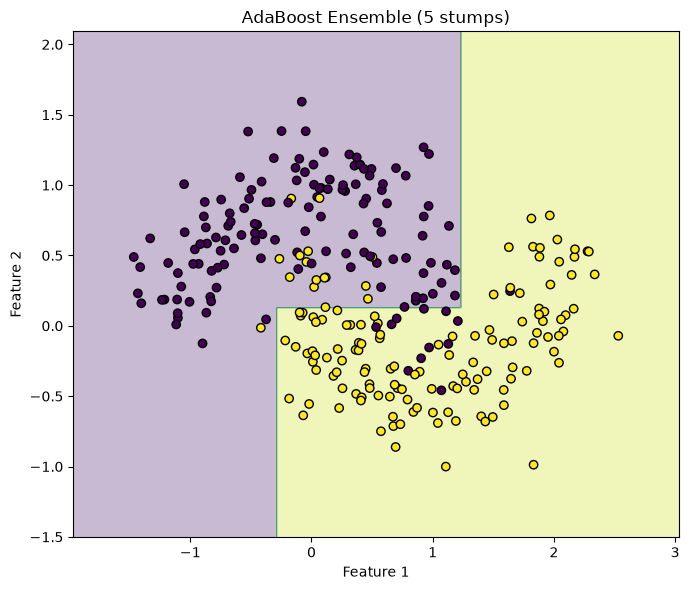

In [98]:
from sklearn.datasets import make_moons

# 1. Generate the moons dataset
X, y = make_moons(
    n_samples=400,
    noise=0.25,
    random_state=0
)

print(f"X shape: {X.shape}, y shape: {y.shape}")

# 2. Split into train/test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=0
)

# 3. Create AdaBoost with 5 decision stumps
base_estimator = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

ada = AdaBoostClassifier(
    estimator=base_estimator,
    n_estimators=5,
    random_state=42
)

# 4. Train AdaBoost
ada.fit(X_train, y_train)

print(f"AdaBoost Training Accuracy: {ada.score(X_train, y_train):.4f}")
print(f"AdaBoost Testing Accuracy: {ada.score(X_test, y_test):.4f}")

# 5. Access the fitted weak learners
estimators = ada.estimators_

print(f"Number of weak learners: {len(estimators)}")
print(f"First weak learner: {estimators[0]}")


def plot_decision_boundary(model, X, y, ax, title):
    # Create a grid of points
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    # Predict the class for every point in the grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot decision regions
    ax.contourf(xx, yy, Z, alpha=0.3)

    # Plot the original data
    ax.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        edgecolor="k"
    )

    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")


fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, estimator in enumerate(estimators):
    plot_decision_boundary(
        estimator,
        X_train,
        y_train,
        axes.flat[i],
        f"Stump {i + 1}"
    )

# Leave the last subplot empty
axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))

plot_decision_boundary(
    ada,
    X_train,
    y_train,
    ax,
    "AdaBoost Ensemble (5 stumps)"
)

plt.tight_layout()
plt.show()



### Step 2.3: XGBoost

[XGBoost](https://xgboost.readthedocs.io/en/stable/) (Extreme Gradient Boosting) is a highly optimized implementation of gradient-boosted trees.  
It is widely used in machine learning competitions (e.g. Kaggle) and real-world applications because it is fast, regularized, and accurate.

Two ways to use XGBoost
- Native API (`xgboost.train`): lower-level, more control.  
- Scikit-learn wrapper (`XGBClassifier`, `XGBRegressor`): works like any sklearn model, with `.fit`, `.predict`, `.score`.  
  - This is what we’ll use here.

#### Why is XGBoost good?
- Multiple parameters to improve generalization (`reg_lambda`, `reg_alpha`, `subsample`, `colsample_bytree`, etc.).
- Highly efficient implementation (multi-threaded, memory optimized).  
- Built-in support for **early stopping**. Instead of fixing the number of trees, XGBoost can monitor performance on a **validation set**.  
    - You train with a large `n_estimators` (e.g. 2000).  
    - If performance does not improve after `early_stopping_rounds` iterations, training stops early.  
    - The best number of trees is saved in `.best_ntree_limit`.

This means: we don’t have to guess the number of trees, XGBoost finds it automatically.

**What to do**
1. Import `XGBClassifier` from `xgboost`.  
2. Fit on the Breast Cancer dataset with parameters (`n_estimators=300, learning_rate=0.1, max_depth=3, subsample=0.8, colsample_bytree=0.8`). Use a validation split and `early_stopping_rounds=20` to automatically select the best number of trees.  
4. Report train/test accuracy; compare to Gradient Boosting and Random Forest.  
5. Inspect `.feature_importances_` and compare to Random Forest.  


X shape: (569, 30)
y shape: (569,)
Best number of trees: 99
XGBoost Training Accuracy: 1.0000
XGBoost Validation Accuracy: 0.9875
XGBoost Testing Accuracy: 0.9649
mean radius: 0.0137
mean texture: 0.0168
mean perimeter: 0.0050
mean area: 0.0137
mean smoothness: 0.0094
mean compactness: 0.0113
mean concavity: 0.0518
mean concave points: 0.0785
mean symmetry: 0.0043
mean fractal dimension: 0.0075
radius error: 0.0063
texture error: 0.0046
perimeter error: 0.0072
area error: 0.0105
smoothness error: 0.0044
compactness error: 0.0040
concavity error: 0.0313
concave points error: 0.0037
symmetry error: 0.0053
fractal dimension error: 0.0101
worst radius: 0.1967
worst texture: 0.0155
worst perimeter: 0.1488
worst area: 0.0423
worst smoothness: 0.0114
worst compactness: 0.0209
worst concavity: 0.0322
worst concave points: 0.1983
worst symmetry: 0.0072
worst fractal dimension: 0.0272
mean radius: RF=0.0777, XGBoost=0.0137
mean texture: RF=0.0082, XGBoost=0.0168
mean perimeter: RF=0.0742, XGBoos

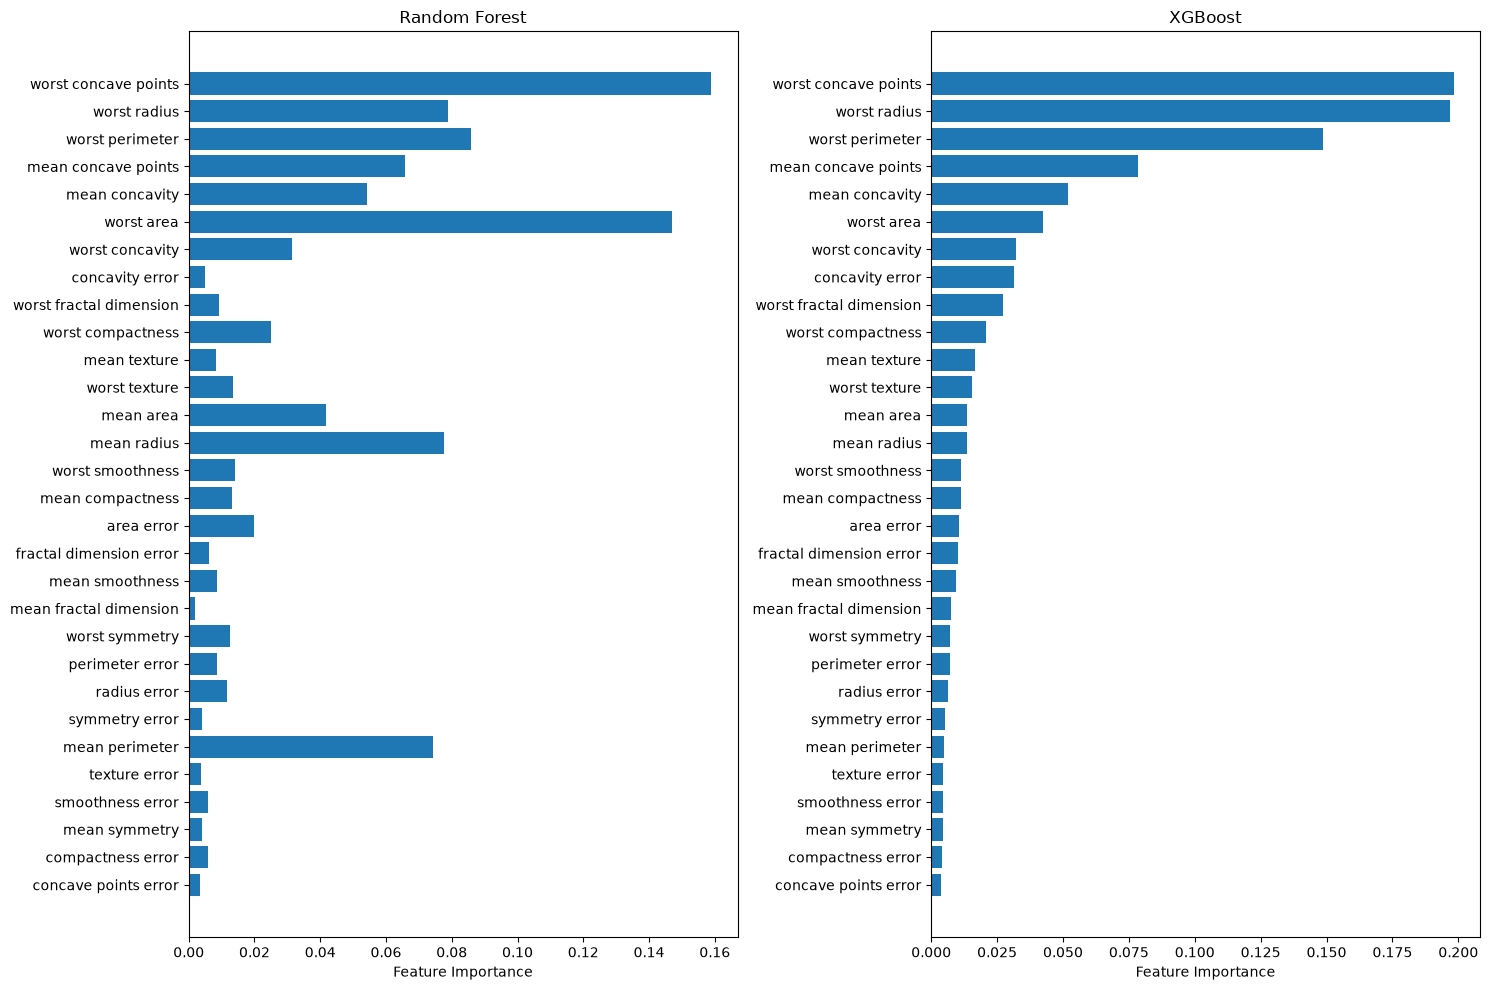

In [99]:
# Load the breast cancer dataset
data = load_breast_cancer()

X = data.data
y = data.target

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_train_xgb, X_val, y_train_xgb, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)


from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    early_stopping_rounds=20,
    random_state=42
)

xgb.fit(
    X_train_xgb,
    y_train_xgb,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print(f"Best number of trees: {xgb.best_iteration + 1}")

print(f"XGBoost Training Accuracy: {xgb.score(X_train_xgb, y_train_xgb):.4f}")
print(f"XGBoost Validation Accuracy: {xgb.score(X_val, y_val):.4f}")
print(f"XGBoost Testing Accuracy: {xgb.score(X_test, y_test):.4f}")

xgb_importances = xgb.feature_importances_

feature_names = data.feature_names
for feature, importance in zip(feature_names, xgb_importances):
    print(f"{feature}: {importance:.4f}")


for feature, rf_imp, xgb_imp in zip(
    feature_names,
    rf_importances,
    xgb_importances
):
    print(f"{feature}: RF={rf_imp:.4f}, XGBoost={xgb_imp:.4f}")


indices = np.argsort(xgb_importances)

fig, axes = plt.subplots(1, 2, figsize=(15, 10))

# Random Forest
axes[0].barh(
    np.array(feature_names)[indices],
    rf_importances[indices]
)
axes[0].set_title("Random Forest")
axes[0].set_xlabel("Feature Importance")

# XGBoost
axes[1].barh(
    np.array(feature_names)[indices],
    xgb_importances[indices]
)
axes[1].set_title("XGBoost")
axes[1].set_xlabel("Feature Importance")

plt.tight_layout()
plt.show()

## 3. Multi-class strategies: OVA and OVO

### Step 3.1: Create a synthetic 4-class dataset (2D)

To study multiclass strategies, we’ll generate a simple 4-class dataset in 2D using `make_blobs`.

**Exact configuration**
- 4 clusters centered at the corners of a square: `(-2, -2), (2, -2), (2, 2), (-2, 2)`
- 200 points per class (total 800 samples)
- Cluster standard deviation = `0.9` 
- Random seed = `7`
- Then apply a small linear transformation to tilt/stretch the blobs, so they are not perfectly axis-aligned. This is done multiplying the generated data by a 2x2 matrix. 

**What to do**
1. Use `make_blobs` with the parameters above to generate `(X_raw, y)`.  
2. Multiply `X_raw` by a matrix `A`. You can set `A = np.array([[-1,1], [0, 0.5]])`  
3. Split into train/test (70/30).  
4. Scatter-plot the training points with colors by class to check the structure.  
5. Define `class_names = ["class 0", "class 1", "class 2", "class 3"]` for later use.  


X_raw shape: (800, 2)
y shape: (800,)
Training set: (560, 2)
Test set: (240, 2)


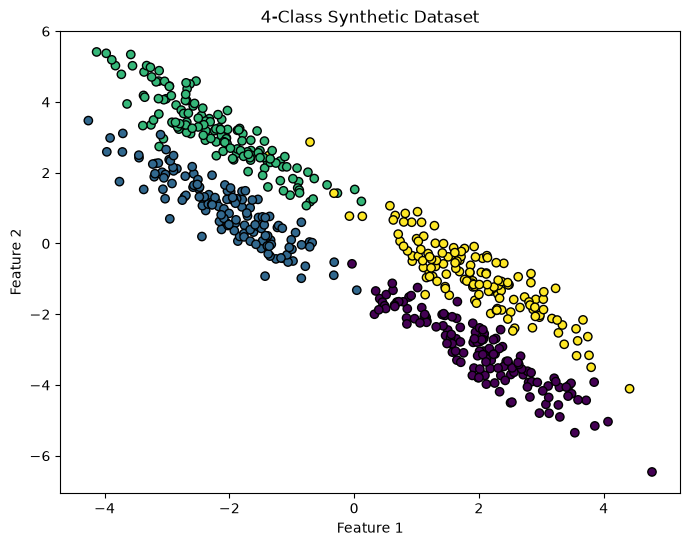

In [100]:
from sklearn.datasets import make_blobs
# Generate the dataset
X_raw, y = make_blobs(
    n_samples=800,
    centers=[
        (-2, -2),
        (2, -2),
        (2, 2),
        (-2, 2)
    ],
    cluster_std=0.9,
    random_state=7
)

print(f"X_raw shape: {X_raw.shape}")
print(f"y shape: {y.shape}")

A = np.array([
    [-1, 1],
    [0, 0.5]
])

X = X_raw @ A

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=7
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")

plt.figure(figsize=(8, 6))

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    edgecolor="k"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("4-Class Synthetic Dataset")

plt.show()

class_names = [
    "class 0",
    "class 1",
    "class 2",
    "class 3"
]

### Step 3.2: OvA vs OvO

Let's compare these two approaches to handle multi-class classification problems.

**What to do**
1. Choose a base learner. Since decision trees can naturally handle multiclass classification, we’ll use Decision Stumps, `max_depth=1`) to make the binary subproblems clear.
2. Fit `OneVsRestClassifier(base)` and `OneVsOneClassifier(base)` on the 4-class training set.
3. Report train/test accuracy for OvR and OvO.
4. Compare intermediate classifiers:
   - OvA: for each class, evaluate the binary task on train/test; report the results in a dataframe, stating which is the fixed class.
   - OvO: for each pair (i, j), restrict to samples of those two classes and evaluate the pairwise binary classifier; report the results in a dataframe, stating which pair of classes are being compared. The comparison order is (0 vs 1, 0 vs 2, 0 vs 3, 1 vs 2, 1 vs 3, 2 vs 3):  combinations(range(K), 2). 
5. Briefly interpret: which class is hardest vs rest? which pairs are most confusable? Relate this to the geometry of your scatter plot.


In [101]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier

# Base learner: Decision Stump
base = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

# OvR and OvO classifiers
ovr = OneVsRestClassifier(base)
ovo = OneVsOneClassifier(base)

# Train
ovr.fit(X_train, y_train)
ovo.fit(X_train, y_train)

print(f"OvR Training Accuracy: {ovr.score(X_train, y_train):.4f}")
print(f"OvR Testing Accuracy:  {ovr.score(X_test, y_test):.4f}")

print(f"OvO Training Accuracy: {ovo.score(X_train, y_train):.4f}")
print(f"OvO Testing Accuracy:  {ovo.score(X_test, y_test):.4f}")


ovr_results = []

for class_id, estimator in enumerate(ovr.estimators_):
    
    # Binary labels: current class = 1, rest = 0
    y_train_binary = (y_train == class_id).astype(int)
    y_test_binary = (y_test == class_id).astype(int)
    
    # Accuracy
    train_accuracy = estimator.score(X_train, y_train_binary)
    test_accuracy = estimator.score(X_test, y_test_binary)
    
    ovr_results.append({
        "Fixed class": class_names[class_id],
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy
    })

ovr_results_df = pd.DataFrame(ovr_results)

display(ovr_results_df)


from itertools import combinations
ovo_results = []

for (class_i, class_j), estimator in zip(
    combinations(range(4), 2),
    ovo.estimators_
):
    
    # Select only samples belonging to the two classes
    train_mask = np.isin(y_train, [class_i, class_j])
    test_mask = np.isin(y_test, [class_i, class_j])
    
    X_train_pair = X_train[train_mask]
    y_train_pair = y_train[train_mask]
    
    X_test_pair = X_test[test_mask]
    y_test_pair = y_test[test_mask]
    
    # Convert labels to binary: class_i = 0, class_j = 1
    y_train_binary = (y_train_pair == class_j).astype(int)
    y_test_binary = (y_test_pair == class_j).astype(int)
    
    train_accuracy = estimator.score(
        X_train_pair,
        y_train_binary
    )
    
    test_accuracy = estimator.score(
        X_test_pair,
        y_test_binary
    )
    
    ovo_results.append({
        "Class pair": f"{class_i} vs {class_j}",
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy
    })

ovo_results_df = pd.DataFrame(ovo_results)

display(ovo_results_df)

OvR Training Accuracy: 0.8536
OvR Testing Accuracy:  0.8250
OvO Training Accuracy: 0.8554
OvO Testing Accuracy:  0.8167


,Fixed class,Train Accuracy,Test Accuracy
0,class 0,0.925000,0.887500
1,class 1,0.750000,0.750000
2,class 2,0.930357,0.945833
3,class 3,0.757143,0.758333


,Class pair,Train Accuracy,Test Accuracy
0,0 vs 1,0.996429,0.983333
1,0 vs 2,1.000000,0.991667
2,0 vs 3,0.850000,0.775000
3,1 vs 2,0.871429,0.850000
4,1 vs 3,0.985714,1.000000
5,2 vs 3,0.989286,1.000000


Interpretation: Class 1 is the hardest class to distinguish from the rest, with a test accuracy of 75.00%. For OvO, the most confusable pair is class 0 vs. class 3, with a test accuracy of 77.50%. This is consistent with the scatter plot, where these classes have more overlapping regions and are therefore harder to separate using a simple decision stump.